Connected to Python 3.13.2

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

ytr = y_train_main.ravel()
yte = y_test.ravel()

try:
    feature_names = preprocess.get_feature_names_out()
except Exception:
    feature_names = None

def plot_pred_vs_true(y_true, y_pred, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, s=20, alpha=0.6, edgecolors='k', linewidths=0.4)
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], 'k--', lw=2, label='y = x')
    plt.xlabel('True GPA')
    plt.ylabel('Predicted GPA')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_residual_hist(y_true, y_pred, title):
    resid = y_pred - y_true
    plt.figure(figsize=(6, 4))
    plt.hist(resid, bins=30, alpha=0.85, edgecolor='k')
    plt.axvline(np.mean(resid), ls='--', lw=2, label=f"Mean: {np.mean(resid):.3f}")
    plt.axvline(np.median(resid), ls='--', lw=2, label=f"Median: {np.median(resid):.3f}")
    plt.xlabel('Residual (Pred - True)')
    plt.ylabel('Frequency')
    plt.title(title)
    plt.legend()
    plt.grid(True, axis='y', alpha=0.3)
    plt.show()

def plot_feature_importance(model, feature_names, title, top_n=20):
    if not hasattr(model, "feature_importances_"):
        return
    importances = model.feature_importances_
    names = np.array(feature_names) if feature_names is not None else np.array([f"f{i}" for i in range(len(importances))])
    idx = np.argsort(importances)[::-1][:top_n]
    plt.figure(figsize=(8, max(4, top_n * 0.35)))
    plt.barh(range(len(idx))[::-1], importances[idx][::-1])
    plt.yticks(range(len(idx))[::-1], names[idx][::-1])
    plt.xlabel("Feature Importance")
    plt.title(title + f" (Top {len(idx)})")
    plt.tight_layout()
    plt.show()

models = {
    "DecisionTree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "KNN": KNeighborsRegressor(n_neighbors=15, weights="distance"),
    "SVR": SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale"),
}

summary_rows = []

for name, clf in models.items():
    print(f"\n=== Training {name} ===")
    clf.fit(X_train_main, ytr)

    # 測試集評估與作圖
    y_pred = clf.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(yte, y_pred)))
    r2   = float(r2_score(yte, y_pred))
    print(f"{name} | Test RMSE={rmse:.4f} | R2={r2:.4f}")
    summary_rows.append({"Model": name, "RMSE": rmse, "R2": r2})

    plot_pred_vs_true(yte, y_pred, title=f"{name}: Prediction vs True (Test)")
    plot_residual_hist(yte, y_pred, title=f"{name}: Residual Distribution (Test)")
    plot_feature_importance(clf, feature_names, title=f"{name}: Feature Importance", top_n=20)

# 總覽比較（只顯示）
results_df = pd.DataFrame(summary_rows).sort_values("R2", ascending=False)
print("\nSummary:\n", results_df.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar(results_df["Model"], results_df["R2"])
plt.ylabel("R^2 (Test)")
plt.title("Model Comparison (R^2)")
plt.grid(True, axis='y', alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE (Test)")
plt.title("Model Comparison (RMSE)")
plt.grid(True, axis='y', alpha=0.3)
plt.show()

NameError: name 'y_train_main' is not defined

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error, mean_absolute_percentage_error 
import matplotlib.pyplot as plt


class NN():
    def __init__(self, input_size, hidden_size, output_size, 
                 seed=None, hidden_activation='relu', leaky_alpha = 0.01):
        self.input_size  = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.hidden_activation = hidden_activation
        self.leaky_alpha = leaky_alpha
        if seed is not None:
            np.random.seed(seed)
      
        # relu use He normalization
        self.weights_input_hidden = np.random.randn(self.input_size,  self.hidden_size) * np.sqrt(2/self.input_size)
        self.weights_hidden_output= np.random.randn(self.hidden_size, self.output_size) * np.sqrt(2/self.hidden_size)
        #initial bias
        self.bias_hidden  = np.zeros((1, self.hidden_size))
        self.bias_output  = np.zeros((1, self.output_size))

        self.output_activation_type = None

    # activations relu max(0,x)
    
    def relu(self, x): 
        return np.maximum(0, x)
    # <0 dead
    def relu_derivative(self, z): 
        return (z > 0).astype(float) 
    def leaky_relu(self, x):
        return np.where(x > 0, x, self.leaky_alpha * x)

    def leaky_relu_derivative(self, z):
        dz = np.ones_like(z)
        dz[z < 0] = self.leaky_alpha
        return dz
    def softmax(self, z):
        z_max = np.max(z, axis=1, keepdims=True)
        e = np.exp(z - z_max)
        return e / np.sum(e, axis=1, keepdims=True)

    def _hidden_forward(self, Z):
        if self.hidden_activation == 'relu':
            return self.relu(Z)
        elif self.hidden_activation == "leaky_relu":
            return self.leaky_relu(Z)
        else:
            raise ValueError("Unsupported activation")

    def _hidden_backward(self, Z_hidden):
        if self.hidden_activation == 'relu':
            return self.relu_derivative(Z_hidden)
        elif self.hidden_activation == 'leaky_relu':
            return self.leaky_relu_derivative(Z_hidden)
        else:
            raise ValueError("Unsupported activation")

    # define feedforward
    def feedforward(self, X, output_activation='linear'):
        self.output_activation_type = output_activation
        # same as np.dot(a,b)
        self.hidden_linear = X @ self.weights_input_hidden + self.bias_hidden
        # call hidden forward if
        self.hidden_output = self._hidden_forward(self.hidden_linear)
        #self.output,activation
        self.output_linear = self.hidden_output @ self.weights_hidden_output + self.bias_output

        
        if output_activation == 'linear':
            self.predicted_output = self.output_linear                 # linear regression
        elif output_activation == 'softmax':
            self.predicted_output = self.softmax(self.output_linear)    
        else:
            raise ValueError("output_activation must be 'sigmoid' or 'linear'")

        return self.predicted_output

    # definr forcast back -= use (y_pred - y) * g'(·)
    def backward(self, X, y, learning_rate):
        y_pred = self.predicted_output
        m = X.shape[0] #batch size 
        #calculate output delta 梯度不變   error 可簡化 
        delta_out = (y_pred - y)/m  # d/dz = 1 batch size normalization causeMSE is np,mean
       
        #sames as np.dot
        dW2 = self.hidden_output.T @ delta_out
        # output bias
        db2 = np.sum(delta_out, axis=0, keepdims=True)
        #caculate the error and delta at hidden
        delta_hidden = (delta_out @ self.weights_hidden_output.T) * self._hidden_backward( self.hidden_linear)
        dW1 = X.T @ delta_hidden
        #hidden bias
        db1 = np.sum(delta_hidden, axis=0, keepdims=True)

        # gardiant decent times learning rate
        self.weights_hidden_output -= learning_rate * dW2
        self.bias_output           -= learning_rate * db2
        self.weights_input_hidden  -= learning_rate * dW1
        self.bias_hidden           -= learning_rate * db1

        """
        def 要加beta = 0.9
        if not hasattr(self, 'v_dW2'):
           self.v_dW2 = np.zeros_like(self.weights_hidden_output)
           self.v_db2 = np.zeros_like(self.bias_output)
           self.v_dW1 = np.zeros_like(self.weights_input_hidden)
           self.v_db1 = np.zeros_like(self.bias_hidden)
           
           初始化VO 第一次訓練時，還沒有過去的「速度」，所以先設為 0。

           更新動量 計算新速度 beta * v_{t-1}：保留部分過去的動量（慣性）
           (1 - beta) * dW：加入當前梯度的影響
           最終的 v_dW2、v_dW1 是一種 平滑後的平均梯度，方向更穩定。
           self.v_dW2 = beta * self.v_dW2 + (1 - beta) * dW2
           self.v_db2 = beta * self.v_db2 + (1 - beta) * db2
           self.v_dW1 = beta * self.v_dW1 + (1 - beta) * dW1
           self.v_db1 = beta * self.v_db1 + (1 - beta) * db1


           使用動量更新權重 減少震盪、加速收斂 使用「平均方向」更新權重，而非單一瞬時梯度

           self.weights_hidden_output -= learning_rate * self.v_dW2
           self.bias_output           -= learning_rate * self.v_db2
           self.weights_input_hidden  -= learning_rate * self.v_dW1
           self.bias_hidden           -= learning_rate * self.v_db1
        
        
        
        """


    def train(self, X, y, X_val=None, y_val=None, epochs= 5000, learning_rate = 0.01, log=2000, error_loss=None, output_activation='linear', loss='auto'):
        assert X.shape[0] == y.shape[0]
        self.history_ = []
        self.rmse_history_ = []
        self.val_history_ = []  
        self.val_rmse_history_ = []  
        for epoch in range(epochs):
            y_pred = self.feedforward(X, output_activation=output_activation)
            
            if output_activation == 'softmax':
            # 交叉熵（加入極小值避免 log(0)）
               eps = 1e-12
               loss = -np.mean(np.sum(y * np.log(np.clip(y_pred, eps, 1 - eps)), axis=1))
               mse = loss  # 統一用 history_ 紀錄（名稱就叫 mse，但實際是 CE）
               rmse = loss
            else:   
               mse = np.mean((y - y_pred) ** 2)  #MSE
               rmse = np.sqrt(mse)               #RMSE  

            
            self.history_.append(mse)       #record
            self.rmse_history_.append(rmse) 

            
            self.backward(X , y , learning_rate)
            if X_val is not None and y_val is not None:
                y_val_pred = self.feedforward(X_val, output_activation=output_activation)
                val_mse = np.mean((y_val - y_val_pred) ** 2)
                val_rmse = np.sqrt(val_mse)
                self.val_history_.append(val_mse)
                self.val_rmse_history_.append(val_rmse)
            
            #set every epoch see
            if epoch % log == 0:
                print(f"Epoch {epoch}, MSE={mse:.6f}, RMSE={rmse:.6f}")
            #same as earlystop    
            if (error_loss is not None) and (mse < error_loss):
                print(f"Early stopping at epoch {epoch}, Loss: {loss}")
                break
        
    
    
    
    def predict(self, X):
        # output is continuous
        return self.feedforward(X, output_activation='linear')
    def plot_loss(self):
        """Plot training loss curve"""
        plt.figure(figsize=(12, 4))
        
        plt.subplot(1, 2, 1)
        plt.plot(self.history_)
        plt.xlabel('Epoch')
        plt.ylabel('MSE')
        plt.title('Training MSE')
        plt.grid(True, alpha=0.3)
        
        plt.subplot(1, 2, 2)
        plt.plot(self.rmse_history_)
        plt.xlabel('Epoch')
        plt.ylabel('RMSE')
        plt.title('Training RMSE')
        plt.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

    def plot_training_validation(self):
        """
        新增：绘制训练集和验证集的 MSE 对比
        """
        if not self.val_history_:
            print("没有验证集数据，请在训练时提供验证集")
            return
        
        plt.figure(figsize=(10, 6))
        plt.plot(self.history_, linewidth=2, label='Train MSE', color='#1f77b4')
        plt.plot(self.val_history_, linewidth=2, label='Validation MSE', color='#ff7f0e')
        plt.xlabel('Epoch', fontsize=12)
        plt.ylabel('MSE', fontsize=12)
        plt.title('Training & Validation Loss', fontsize=14, fontweight='bold')
        plt.legend(fontsize=11, loc='upper right')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
def evaluate_accuracy(y_true, y_pred, threshold=0.1):
    """
    評估預測準確率
    
    參數:
    - y_true: 真實值
    - y_pred: 預測值
    - threshold: 誤差閾值（預設 0.1，表示誤差 ≤ 0.1 視為準確）
    
    返回: 包含多種準確率指標的字典
    """
    y_true = y_true.ravel()
    y_pred = y_pred.ravel()
    
    # 1. R² 分數 (越接近 1 越好)
    r2 = r2_score(y_true, y_pred)
    
    # 2. RMSE (均方根誤差)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    # 3. MAE (平均絕對誤差)
    mae = mean_absolute_error(y_true, y_pred)
    
    # 4. MAPE (平均絕對百分比誤差) - 用於理解相對誤差
    try:
        mape = mean_absolute_percentage_error(y_true, y_pred)
    except:
        mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-10))) * 100
    
    # 5. 預測準確率 (Accuracy within threshold) - 誤差在閾值內的比例
    within_threshold = np.mean(np.abs(y_true - y_pred) <= threshold) * 100
    
    # 6. 預測準確率 ±0.05 等級
    within_05 = np.mean(np.abs(y_true - y_pred) <= 0.05) * 100
    within_15 = np.mean(np.abs(y_true - y_pred) <= 0.15) * 100
    within_20 = np.mean(np.abs(y_true - y_pred) <= 0.20) * 100
    
    # 7. 最大誤差和最小誤差
    errors = np.abs(y_true - y_pred)
    max_error = np.max(errors)
    min_error = np.min(errors)
    
    return {
        'R²': r2,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        f'Accuracy (±{threshold})': within_threshold,
        'Accuracy (±0.05)': within_05,
        'Accuracy (±0.15)': within_15,
        'Accuracy (±0.20)': within_20,
        'Max Error': max_error,
        'Min Error': min_error
    }


def print_accuracy_report(metrics, model_name="Model"):
    """以表格形式顯示準確率報告"""
    print(f"\n{'='*60}")
    print(f"{model_name} - 預測準確率評估")
    print(f"{'='*60}")
    print(f"R² 分數:                    {metrics['R²']:.4f} ")
    print(f"RMSE (均方根誤差):          {metrics['RMSE']:.4f}")
    print(f"MAE (平均絕對誤差):         {metrics['MAE']:.4f}")
    print(f"MAPE (平均絕對百分比誤差):  {metrics['MAPE']:.2f}%")
    print(f"\n預測準確率:")
    print(f"  ± 0.05 範圍內:            {metrics['Accuracy (±0.05)']:.2f}%")
    print(f"  ± 0.15 範圍內:            {metrics['Accuracy (±0.15)']:.2f}%")
    print(f"  ± 0.20 範圍內:            {metrics['Accuracy (±0.20)']:.2f}%")
    print(f"\n誤差統計:")
    print(f"  最大誤差:                  {metrics['Max Error']:.4f}")
    print(f"  最小誤差:                  {metrics['Min Error']:.4f}")
    print(f"{'='*60}\n")


def plot_predictions_with_accuracy(y_true, y_pred, model_info="Best Model"):
    """繪製預測結果並標註準確率"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    y_true = y_true.ravel()
    y_pred = y_pred.ravel()
    errors = np.abs(y_true - y_pred)
    
    # 左圖: 預測值 vs 真實值
    ax1 = axes[0]
    scatter = ax1.scatter(y_true, y_pred, c=errors, cmap='RdYlGn_r', alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
    minv = min(y_true.min(), y_pred.min())
    maxv = max(y_true.max(), y_pred.max())
    ax1.plot([minv, maxv], [minv, maxv], 'k--', linewidth=2, label='Perfect Prediction')
    ax1.set_xlabel('True GPA', fontsize=12)
    ax1.set_ylabel('Predicted GPA', fontsize=12)
    ax1.set_title('Prediction vs True Values', fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    cbar = plt.colorbar(scatter, ax=ax1)
    cbar.set_label('Absolute Error', fontsize=10)
    
    # 右圖: 誤差分佈
    ax2 = axes[1]
    ax2.hist(errors, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
    ax2.axvline(np.mean(errors), color='red', linestyle='--', linewidth=2, label=f'Mean Error: {np.mean(errors):.4f}')
    ax2.axvline(np.median(errors), color='green', linestyle='--', linewidth=2, label=f'Median Error: {np.median(errors):.4f}')
    ax2.set_xlabel('Absolute Error', fontsize=12)
    ax2.set_ylabel('Frequency', fontsize=12)
    ax2.set_title('Error Distribution', fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.legend()
    
    fig.suptitle(model_info, fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()
#資料

In [ ]:
df = pd.read_csv("Student_performance_data _.csv")


TARGET = "GPA"
drop_cols = [c for c in ["GPA", "GradeClass"] if c in df.columns]
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET])

X = df.drop(columns=drop_cols, errors="ignore")
y = df[TARGET].values.reshape(-1, 1)

# 型別偵測 + 強制數值
num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
forced_numeric = []
for c in cat_cols:
    tmp = pd.to_numeric(X[c], errors="coerce")
    if tmp.notna().mean() >= 0.9:
        X[c] = tmp
        forced_numeric.append(c)
if forced_numeric:
    num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

# 前處理器
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", ohe),
])
preprocess = ColumnTransformer(
    transformers=[("num", numeric_tf, num_cols), ("cat", categorical_tf, cat_cols)],
    remainder="drop"
)
# split（先切再 fit 前處理，避免洩漏）
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# 【重要】從訓練集中再分出驗證集
X_train_main_df, X_val_df, y_train_main, y_val = train_test_split(
    X_train_df, y_train, test_size=0.2, random_state=42
)

preprocess.fit(X_train_main_df)
X_train_main = preprocess.transform(X_train_main_df).astype(np.float32)
X_val = preprocess.transform(X_val_df).astype(np.float32)
X_test = preprocess.transform(X_test_df).astype(np.float32)
y_train_main = y_train_main.astype(np.float32)
y_val = y_val.astype(np.float32)
y_test = y_test.astype(np.float32)

print("[Info] X_train shape:", X_train_main.shape, "| X_val shape:", X_val.shape, "| X_test shape:", X_test.shape)

[Info] X_train shape: (1530, 13) | X_val shape: (383, 13) | X_test shape: (479, 13)



=== Training DecisionTree ===
DecisionTree | Test RMSE=0.3169 | R2=0.8786


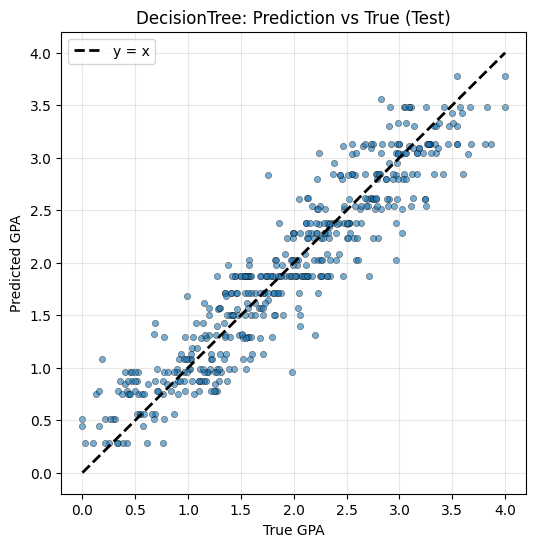

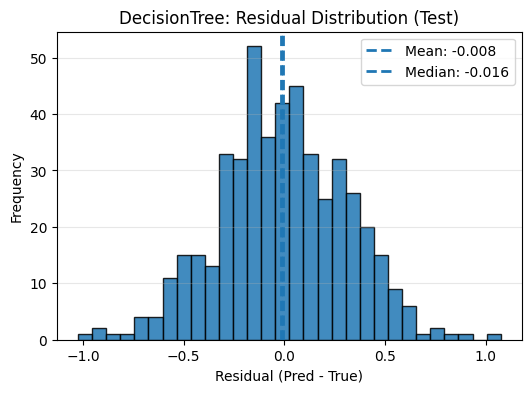

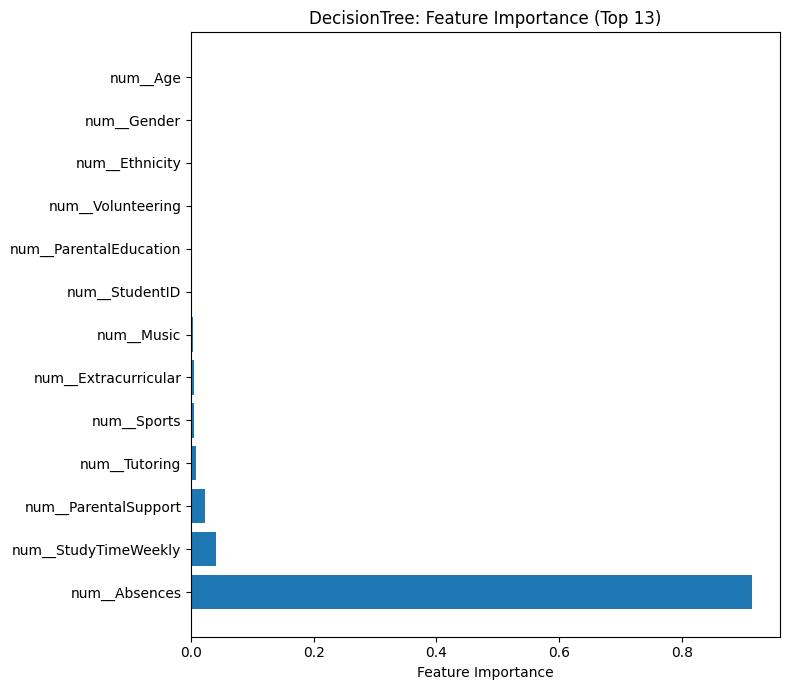


=== Training RandomForest ===
RandomForest | Test RMSE=0.2517 | R2=0.9234


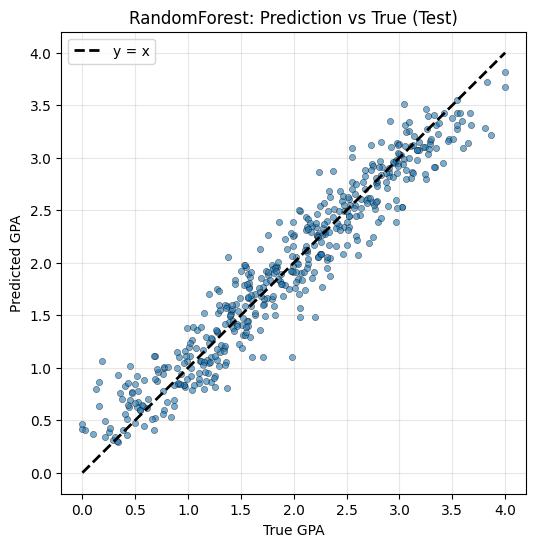

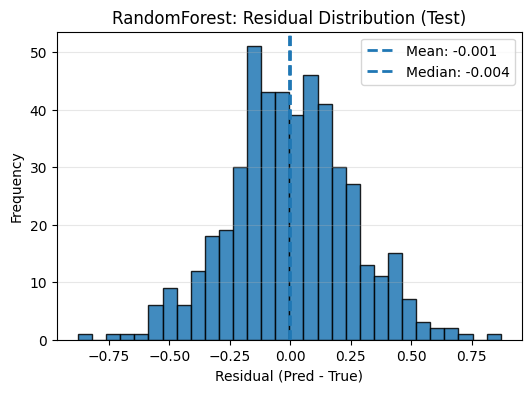

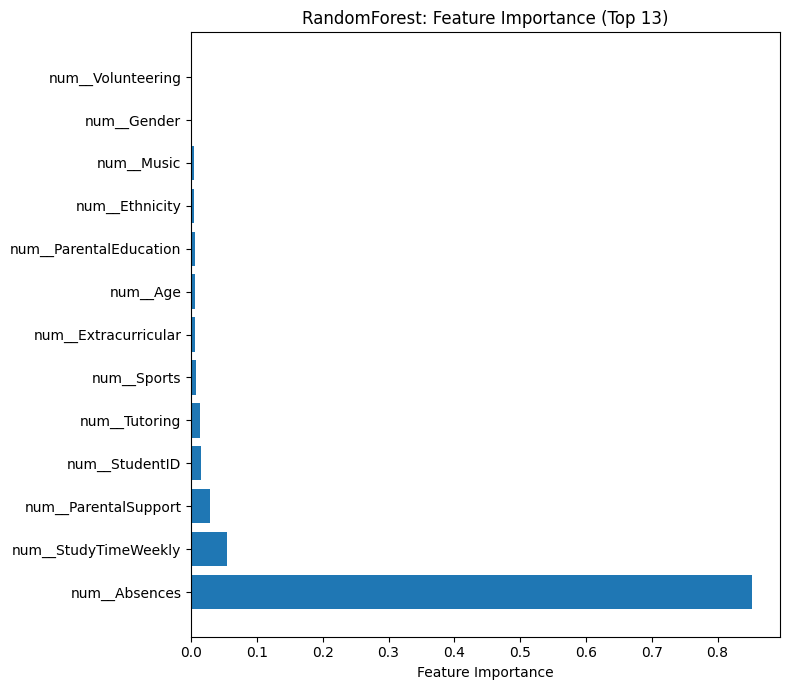


=== Training KNN ===
KNN | Test RMSE=0.4503 | R2=0.7548


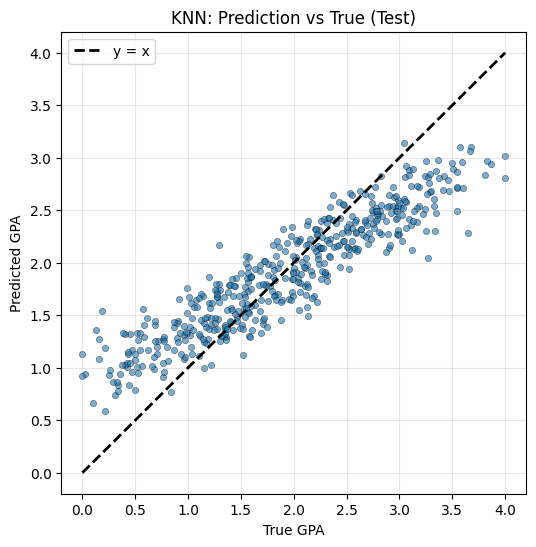

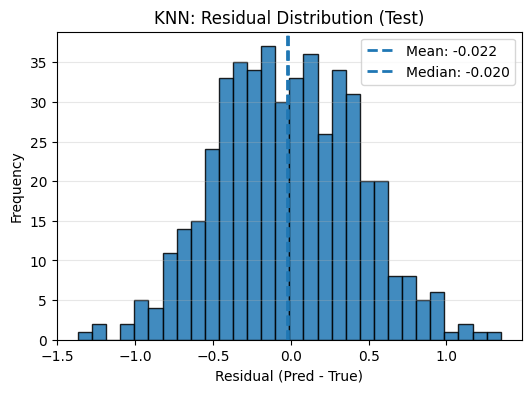


=== Training SVR ===
SVR | Test RMSE=0.2600 | R2=0.9182


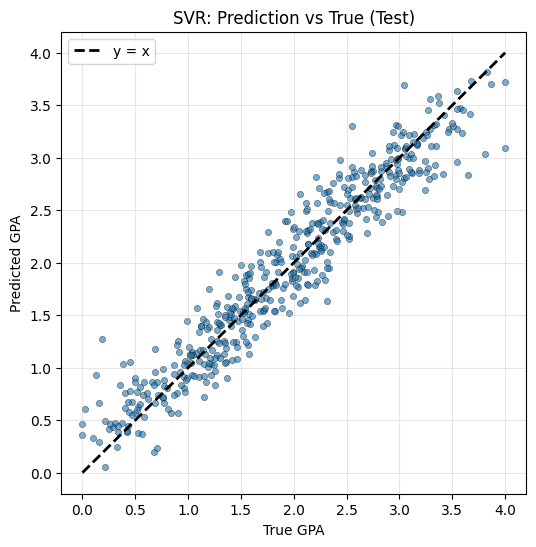

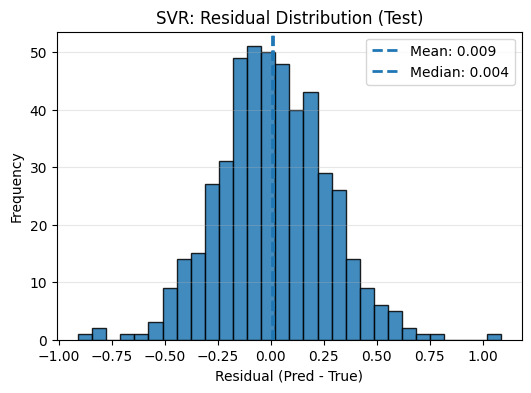


Summary:
        Model     RMSE       R2
RandomForest 0.251737 0.923365
         SVR 0.260007 0.918247
DecisionTree 0.316851 0.878594
         KNN 0.450311 0.754781


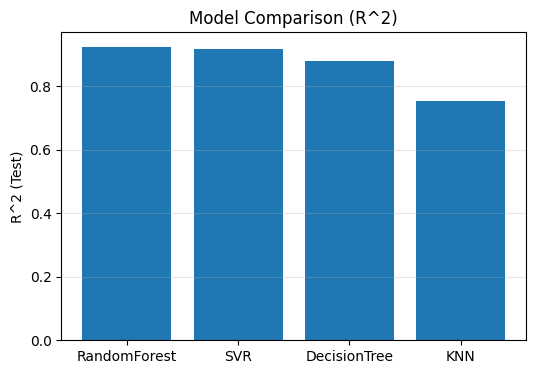

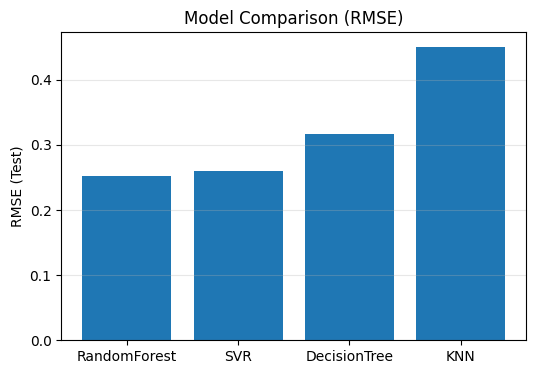

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

ytr = y_train_main.ravel()
yte = y_test.ravel()

try:
    feature_names = preprocess.get_feature_names_out()
except Exception:
    feature_names = None

def plot_pred_vs_true(y_true, y_pred, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, s=20, alpha=0.6, edgecolors='k', linewidths=0.4)
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], 'k--', lw=2, label='y = x')
    plt.xlabel('True GPA')
    plt.ylabel('Predicted GPA')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_residual_hist(y_true, y_pred, title):
    resid = y_pred - y_true
    plt.figure(figsize=(6, 4))
    plt.hist(resid, bins=30, alpha=0.85, edgecolor='k')
    plt.axvline(np.mean(resid), ls='--', lw=2, label=f"Mean: {np.mean(resid):.3f}")
    plt.axvline(np.median(resid), ls='--', lw=2, label=f"Median: {np.median(resid):.3f}")
    plt.xlabel('Residual (Pred - True)')
    plt.ylabel('Frequency')
    plt.title(title)
    plt.legend()
    plt.grid(True, axis='y', alpha=0.3)
    plt.show()

def plot_feature_importance(model, feature_names, title, top_n=20):
    if not hasattr(model, "feature_importances_"):
        return
    importances = model.feature_importances_
    names = np.array(feature_names) if feature_names is not None else np.array([f"f{i}" for i in range(len(importances))])
    idx = np.argsort(importances)[::-1][:top_n]
    plt.figure(figsize=(8, max(4, top_n * 0.35)))
    plt.barh(range(len(idx))[::-1], importances[idx][::-1])
    plt.yticks(range(len(idx))[::-1], names[idx][::-1])
    plt.xlabel("Feature Importance")
    plt.title(title + f" (Top {len(idx)})")
    plt.tight_layout()
    plt.show()

models = {
    "DecisionTree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "KNN": KNeighborsRegressor(n_neighbors=15, weights="distance"),
    "SVR": SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale"),
}

summary_rows = []

for name, clf in models.items():
    print(f"\n=== Training {name} ===")
    clf.fit(X_train_main, ytr)

    # 測試集評估與作圖
    y_pred = clf.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(yte, y_pred)))
    r2   = float(r2_score(yte, y_pred))
    print(f"{name} | Test RMSE={rmse:.4f} | R2={r2:.4f}")
    summary_rows.append({"Model": name, "RMSE": rmse, "R2": r2})

    plot_pred_vs_true(yte, y_pred, title=f"{name}: Prediction vs True (Test)")
    plot_residual_hist(yte, y_pred, title=f"{name}: Residual Distribution (Test)")
    plot_feature_importance(clf, feature_names, title=f"{name}: Feature Importance", top_n=20)

# 總覽比較（只顯示）
results_df = pd.DataFrame(summary_rows).sort_values("R2", ascending=False)
print("\nSummary:\n", results_df.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar(results_df["Model"], results_df["R2"])
plt.ylabel("R^2 (Test)")
plt.title("Model Comparison (R^2)")
plt.grid(True, axis='y', alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE (Test)")
plt.title("Model Comparison (RMSE)")
plt.grid(True, axis='y', alpha=0.3)
plt.show()

In [ ]:
# ========= Hyperparameter Sweep (GPA regression) =========
hidden_sizes   = [16, 32, 48, 64]
learning_rates = [0.0005, 0.001, 0.002, 0.005]

results = []
best_model = None
best_score = -np.inf  # 用 R^2 當主指標

for h in hidden_sizes:
    for lr in learning_rates:
        print(f"\nTraining with hidden_size={h}, learning_rate={lr}")
        model = NN(
            input_size=X_train_main.shape[1],
            hidden_size=h,
            output_size=1,
            seed=42,
            hidden_activation='leaky_relu',
            leaky_alpha=0.01
        )

        model.train(
            X_train_main, y_train_main,
            X_val=X_val, y_val=y_val, 
            epochs=5000,
            learning_rate=lr,
            output_activation='linear',
            log=500
        )

        y_pred = model.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test.ravel(), y_pred.ravel()))
        r2   = r2_score(y_test.ravel(), y_pred.ravel())

        results.append({
            "hidden_size": h,
            "learning_rate": lr,
            "final_loss": float(model.history_[-1]),
            "test_RMSE": float(rmse),
            "test_R2": float(r2)
        })

        # 挑最好的（R^2 最大）
        if r2 > best_score:
            best_score = r2
            best_model = (h, lr, model, y_pred)

results_df = pd.DataFrame(results).sort_values(
    ["test_R2", "test_RMSE"], ascending=[False, True]
)
print("\n===== Grid Results (Regression) =====")
print(results_df.to_string(index=False))


Training with hidden_size=16, learning_rate=0.0005
Epoch 0, MSE=4.335789, RMSE=2.082256
Epoch 500, MSE=2.051854, RMSE=1.432429
Epoch 1000, MSE=1.244363, RMSE=1.115510
Epoch 1500, MSE=0.872849, RMSE=0.934264
Epoch 2000, MSE=0.670560, RMSE=0.818877
Epoch 2500, MSE=0.547297, RMSE=0.739795
Epoch 3000, MSE=0.466297, RMSE=0.682860
Epoch 3500, MSE=0.410574, RMSE=0.640761
Epoch 4000, MSE=0.369971, RMSE=0.608252
Epoch 4500, MSE=0.339033, RMSE=0.582265

Training with hidden_size=16, learning_rate=0.001
Epoch 0, MSE=4.335789, RMSE=2.082256
Epoch 500, MSE=1.243907, RMSE=1.115306
Epoch 1000, MSE=0.670387, RMSE=0.818772
Epoch 1500, MSE=0.466219, RMSE=0.682802
Epoch 2000, MSE=0.369927, RMSE=0.608216
Epoch 2500, MSE=0.314909, RMSE=0.561168
Epoch 3000, MSE=0.279658, RMSE=0.528827
Epoch 3500, MSE=0.253934, RMSE=0.503919
Epoch 4000, MSE=0.234160, RMSE=0.483901
Epoch 4500, MSE=0.218468, RMSE=0.467405

Training with hidden_size=16, learning_rate=0.002
Epoch 0, MSE=4.335789, RMSE=2.082256
Epoch 500, MSE=0.


[Best] hidden_size=64, learning_rate=0.005 | Test R²=0.9160


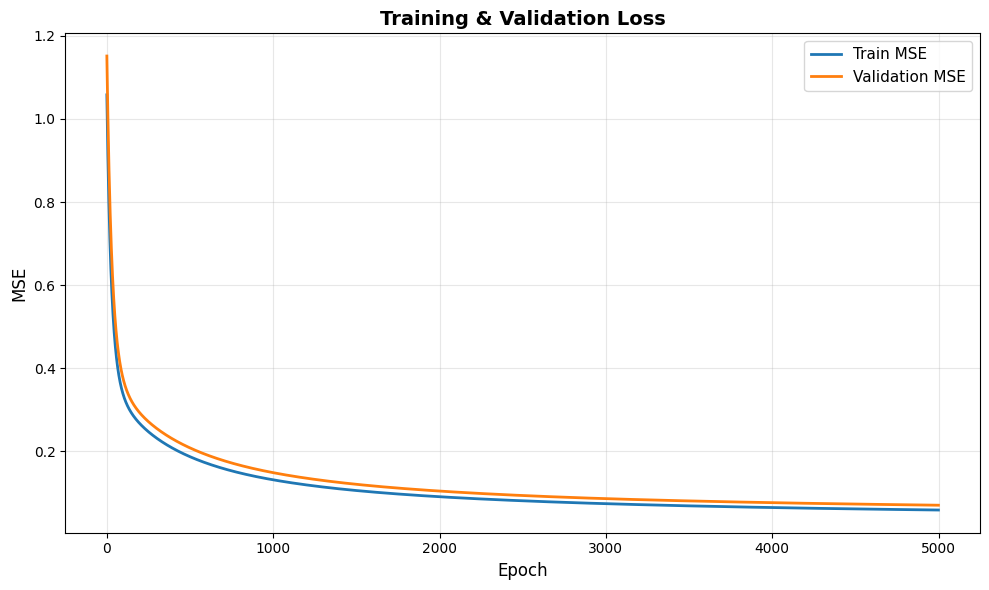

  0%|          | 0/200 [00:00<?, ?it/s]

[SHAP] force plot saved to: c:\Users\jerry\OneDrive\桌面\ANN\reports\force_agg.html


<ipython-input-6-e672d3dad5f6>:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_explain, feature_names=feature_names)


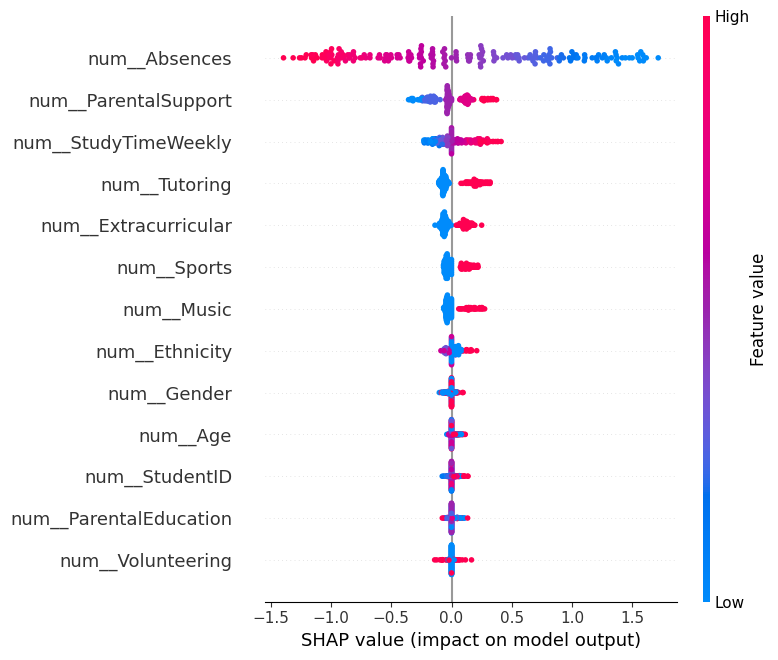

<ipython-input-6-e672d3dad5f6>:51: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_explain, feature_names=feature_names, plot_type='bar')


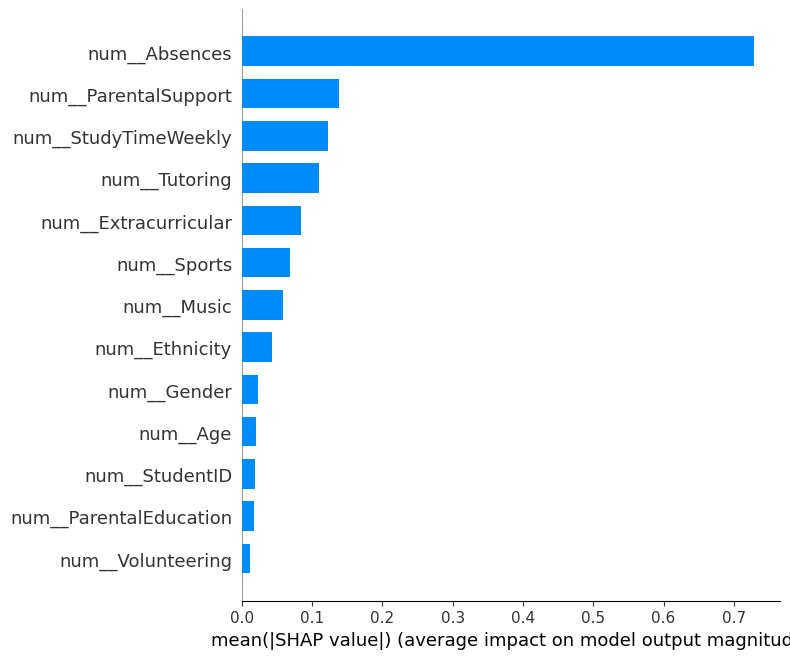

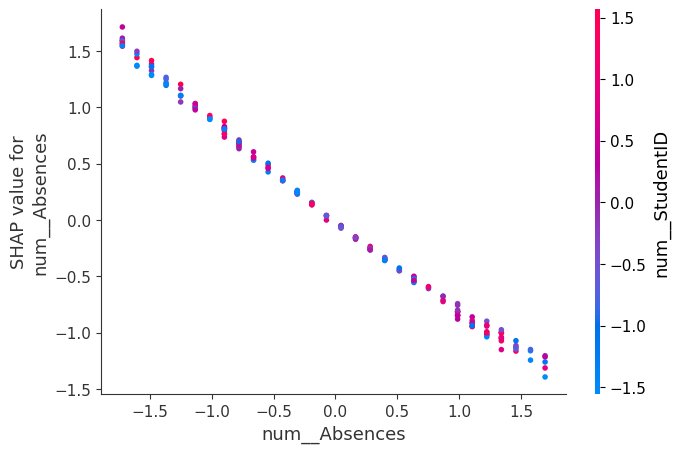


Neural Network (h=64, lr=0.005) - 預測準確率評估
R² 分數:                    0.9160 
RMSE (均方根誤差):          0.2636
MAE (平均絕對誤差):         0.2132
MAPE (平均絕對百分比誤差):  8506895317588.56%

預測準確率:
  ± 0.05 範圍內:            12.73%
  ± 0.15 範圍內:            42.80%
  ± 0.20 範圍內:            54.91%

誤差統計:
  最大誤差:                  0.8627
  最小誤差:                  0.0014



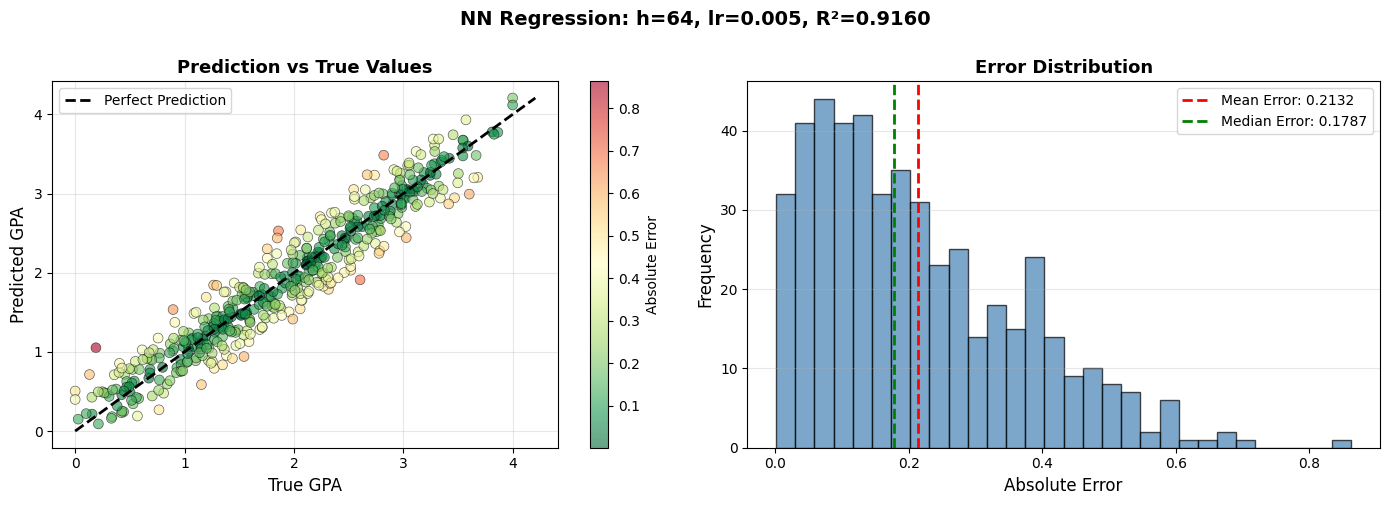

In [ ]:
# ========= 最佳模型的準確率評估與視覺化 =========
if best_model is not None:
    h, lr, model, y_pred = best_model
    print(f"\n[Best] hidden_size={h}, learning_rate={lr} | Test R²={best_score:.4f}")
    # 新增：繪製訓練和驗證曲線
    model.plot_training_validation()


    import os, webbrowser
    import shap
    import numpy as np

    # 已前處理後的欄位名稱（One-Hot 展開後）
    feature_names = preprocess.get_feature_names_out()

    # 背景分佈（用訓練集 processed 的代表子集，加速）
    background = shap.kmeans(X_train_main, 50)   # 或 shap.sample(X_train_main, 200)

    # 模型預測函數，回傳 1D
    f = lambda X: model.predict(X).ravel()

    # 從測試集抽樣一些樣本做解釋（KernelExplainer 較慢）
    n_explain = min(200, X_test.shape[0])
    idx = np.random.choice(X_test.shape[0], size=n_explain, replace=False)
    X_explain = X_test[idx]

    explainer = shap.KernelExplainer(f, background)
    shap_values = explainer.shap_values(X_explain)  # (n_explain, n_features)
    
    y_explain_pred = f(X_explain)                   # 你的 NN 預測 (n_explain,)
    y_explain_true = y_test[idx].ravel()            # 對應真值 (n_explain,)
    i = int(np.argmax(np.abs(y_explain_true - y_explain_pred)))

    os.makedirs("reports", exist_ok=True)

    # 2) FORCE PLOT：存成 HTML 並自動打開（VS Code 腳本最穩）
    shap.initjs()
    force_all = shap.force_plot(
    explainer.expected_value,
    shap_values,
    X_explain,
    feature_names=feature_names
     )
    force_html = os.path.abspath("reports/force_agg.html")
    shap.save_html(force_html, force_all)
    print(f"[SHAP] force plot saved to: {force_html}")
    webbrowser.open(f"file://{force_html}")
    # 全局重要度
    shap.summary_plot(shap_values, X_explain, feature_names=feature_names)
    shap.summary_plot(shap_values, X_explain, feature_names=feature_names, plot_type='bar')

    # （選）看最重要特徵的依賴圖
    mean_abs = np.mean(np.abs(shap_values), axis=0)
    top_idx = int(np.argmax(mean_abs))
    shap.dependence_plot(top_idx, shap_values, X_explain, feature_names=feature_names)
    # ===== SHAP：到這裡結束 =====
    # 計算準確率指標
    metrics = evaluate_accuracy(y_test, y_pred, threshold=0.1)
    
    # 打印詳細報告
    print_accuracy_report(metrics, f"Neural Network (h={h}, lr={lr})")
    
    # 繪製預測結果和準確率分佈
    plot_predictions_with_accuracy(
        y_test, y_pred, 
        f"NN Regression: h={h}, lr={lr}, R²={best_score:.4f}"
    )